
Building summary table...


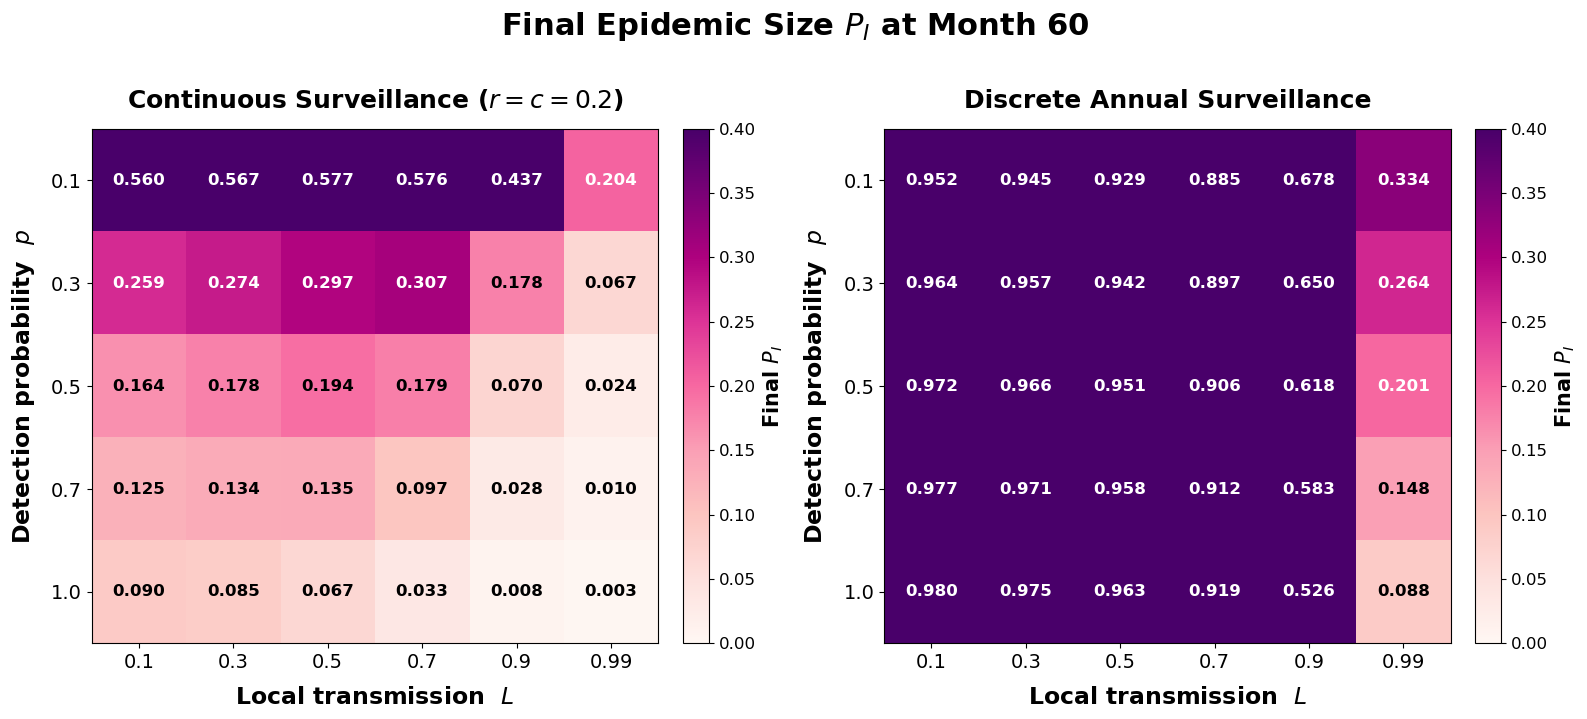

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Parameters
beta = 0.82
rho  = 1.0 / 10.53
N    = 625

t_total         = 60
survey_interval = 12
steps_per_year  = 500
n_surveys       = t_total // survey_interval

#  Initial conditions
def get_y0(N=625):
    PE = 1.0 / N
    PS = 1.0 - PE
    return [PS, PE, PS*PS, PS*PE, 0.0, PE*PE, 0.0]

def get_y0_cont(N=625):
    PE = 1.0 / N
    PS = 1.0 - PE
    return [PS, PE, 0.0, PS*PS, PS*PE, 0.0, PE*PE, 0.0, 0.0]



#  Free SEI ODE (no control) 
def sei_free(t, y, beta, rho, L):
    PS, PE, PSS, PSE, PSI, PEE, PEI = y
    PI = 1.0 - PS - PE
    qIS = PSI/PS if PS > 1e-12 else 0.0
    inf_S  = (1-L)*PI + L*qIS
    inf_SS = (1-L)*PI + 0.75*L*qIS
    inf_SI = (1-L)*PI + 0.25*L + 0.75*L*qIS
    dPS  = -beta*PS*inf_S
    dPE  =  beta*PS*inf_S - rho*PE
    dPSS = -2*beta*PSS*inf_SS
    dPSE =  beta*PSS*inf_SS - beta*PSE*inf_SS - rho*PSE
    dPSI =  rho*PSE - beta*PSI*inf_SI
    dPEE =  2*beta*PSE*inf_SS - 2*rho*PEE
    dPEI =  rho*PEE + beta*PSI*inf_SI - rho*PEI
    return [dPS, dPE, dPSS, dPSE, dPSI, dPEE, dPEI]


# Annual survey update 
def apply_survey(state, p):
    PS, PE, PSS, PSE, PSI, PEE, PEI = state
    PI = 1.0 - PS - PE
    detected_I = p * PI
    PS_new = max(PS - p*PSI, 0.0)
    PE_new = max(PE - p*PEI, 0.0)
    PI_new = max(PI - detected_I, 0.0)
    fS = PS_new/PS if PS > 1e-12 else 0.0
    fE = PE_new/PE if PE > 1e-12 else 0.0
    fI = PI_new/PI if PI > 1e-12 else 0.0
    return [PS_new, PE_new,
            max(PSS*fS*fS, 0.0), max(PSE*fS*fE, 0.0),
            max(PSI*fS*fI, 0.0), max(PEE*fE*fE, 0.0),
            max(PEI*fE*fI, 0.0)]

# Continuous control ODE 
def sei_continuous(t, y, beta, rho, L, r, c, p):
    PS, PE, PI, PSS, PSE, PSI, PEE, PEI, PII = y
    qIS = PSI/PS if PS > 1e-12 else 0.0
    qIE = PEI/PE if PE > 1e-12 else 0.0
    pr = p*r;  pc = p*c
    inf_S  = (1-L)*PI + L*qIS
    inf_SS = (1-L)*PI + 0.75*L*qIS
    inf_SI = (1-L)*PI + 0.25*L + 0.75*L*qIS
    dPS  = -beta*PS*inf_S - pc*PSI
    dPE  =  beta*PS*inf_S - rho*PE - pc*PEI
    dPI  =  rho*PE - pr*PI
    dPSS = -2*beta*PSS*inf_SS - 2*pc*PSS*qIS
    dPSE = ( beta*PSS*inf_SS - beta*PSE*inf_SS
            -rho*PSE - pc*PSE*qIS - pc*PEI*qIE)
    dPSI = ( rho*PSE - beta*PSI*inf_SI
            -pr*PSI - pc*PSI*(0.25+0.75*qIS))
    dPEE = ( 2*beta*PSE*inf_SS - 2*rho*PEE - 2*pc*PEE*qIE)
    dPEI = ( rho*PEE + beta*PSI*inf_SI
            -rho*PEI - pr*PEI - pc*PEI*(0.25+0.75*qIE))
    dPII = 2*rho*PEI - 2*pr*PII
    return [dPS,dPE,dPI,dPSS,dPSE,dPSI,dPEE,dPEI,dPII]


#  Run functions 
def run_discrete(p, L_val):
    state = get_y0()
    all_t, all_PI = [], []
    t_now = 0.0
    for _ in range(n_surveys):
        t_chunk = np.linspace(t_now, t_now+survey_interval,
                              steps_per_year)
        sol = solve_ivp(sei_free, [t_now, t_now+survey_interval],
                        state, args=(beta, rho, L_val),
                        t_eval=t_chunk, method='Radau',
                        rtol=1e-8, atol=1e-10)
        all_t.append(sol.t)
        all_PI.append(1.0 - sol.y[0] - sol.y[1])
        state_end = [sol.y[i][-1] for i in range(7)]
        state = apply_survey(state_end, p)
        t_now += survey_interval
    return (np.concatenate(all_t),
            np.concatenate(all_PI))

def run_continuous(p, L_val, r=0.2, c=0.2):
    y0 = get_y0_cont()
    t_e = np.linspace(0, t_total, 3000)
    sol = solve_ivp(sei_continuous, [0, t_total], y0,
                    args=(beta, rho, L_val, r, c, p),
                    t_eval=t_e, method='Radau',
                    rtol=1e-8, atol=1e-10)
    return sol.t, sol.y[2]


p_grid = [0.1, 0.3, 0.5, 0.7, 1.0]
L_grid = [0.1, 0.3, 0.5, 0.7, 0.9, 0.99]

cont_matrix = np.zeros((len(p_grid), len(L_grid)))
disc_matrix = np.zeros((len(p_grid), len(L_grid)))

print("\nBuilding summary table...")

for i, pv in enumerate(p_grid):
    for j, Lv in enumerate(L_grid):

        _, PI_c = run_continuous(pv, Lv)
        _, PI_d = run_discrete(pv, Lv)

        cont_matrix[i, j] = PI_c[-1]
        disc_matrix[i, j] = PI_d[-1]


# ============================================================
# Plotting
# ============================================================

fig3, axes3 = plt.subplots(
    1, 2,
    figsize=(16, 7)
)

fig3.suptitle(
    'Final Epidemic Size $P_I$ at Month 60',
    fontsize=22,
    fontweight='bold',
    y=1.02
)

for ax3, matrix, title in zip(
        axes3,
        [cont_matrix, disc_matrix],
        ['Continuous Surveillance ($r=c=0.2$)',
         'Discrete Annual Surveillance']):

    # Better colormap for readability
    im = ax3.imshow(
        matrix,
        cmap='RdPu',
        aspect='auto',
        vmin=0,
        vmax=0.4
    )

    # Axis ticks
    ax3.set_xticks(range(len(L_grid)))
    ax3.set_yticks(range(len(p_grid)))

    # Tick labels
    ax3.set_xticklabels(
        [str(l) for l in L_grid],
        fontsize=14
    )

    ax3.set_yticklabels(
        [str(p) for p in p_grid],
        fontsize=14
    )

    # Axis labels
    ax3.set_xlabel(
        'Local transmission  $L$',
        fontsize=17,
        fontweight='bold',
        labelpad=10
    )

    ax3.set_ylabel(
        'Detection probability  $p$',
        fontsize=17,
        fontweight='bold',
        labelpad=10
    )

    # Panel title
    ax3.set_title(
        title,
        fontsize=18,
        fontweight='bold',
        pad=15
    )

    # Add cell values
    for i in range(len(p_grid)):
        for j in range(len(L_grid)):

            value = matrix[i, j]

            ax3.text(
                j,
                i,
                f'{value:.3f}',
                ha='center',
                va='center',
                fontsize=12,
                fontweight='bold',
                color='white' if value > 0.20 else 'black'
            )

    # Colorbar
    cbar = plt.colorbar(
        im,
        ax=ax3,
        fraction=0.046,
        pad=0.04
    )

    cbar.set_label(
        'Final $P_I$',
        fontsize=15,
        fontweight='bold'
    )

    cbar.ax.tick_params(labelsize=12)

# Improve spacing
plt.tight_layout()

# Save figure
plt.savefig(
    'improved_heatmap.png',
    dpi=300,
    bbox_inches='tight'
)
plt.savefig('Dicrete',
            dpi=150, bbox_inches='tight')
plt.show()